# LightGBM feature experiments, round 2

Same model, same hyperparameters as the baseline. **Only the input features change.**
Round 1 found that recipe popularity drove almost all of the gain. This round:

- **Stage 1:** do additional popularity signals (seasonality, trend/decay, 5-star popularity) add anything on top of `baseline + recipe_pop`?
- **Stage 2:** on top of the best popularity set, do user features (activity, taste, taste + interactions) add anything?

Every row is compared against the other rows *in this notebook*, run on the same quarters. Don't compare these numbers directly to round 1 if `STRIDE` differs.
Run on `val` only.

In [1]:
import sys, time
sys.path.insert(0, "../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from remy.splits import RollingSplits, SPLIT_DIR
from remy.model.lightgbm_features import LightGBM, GROUP_COLS, BASELINE_GROUPS, ALL_ROUND1
from remy.evaluate import evaluate_quarter

splits = RollingSplits()
SPLIT = "val"
STRIDE = 1          # 4 = every 4th quarter (fast exploration); 1 = all 16 quarters
quarters = splits.evaluation_quarters(SPLIT)[::STRIDE]
METRICS = ["NDCG", "HR@10", "HR@100", "Recall@10", "Recall@100"]
print(f"{len(quarters)} eval quarters:", [q.start.date() for q in quarters])
print({g: len(c) for g, c in GROUP_COLS.items()})

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


16 eval quarters: [datetime.date(2007, 1, 1), datetime.date(2007, 4, 1), datetime.date(2007, 7, 1), datetime.date(2007, 10, 1), datetime.date(2008, 1, 1), datetime.date(2008, 4, 1), datetime.date(2008, 7, 1), datetime.date(2008, 10, 1), datetime.date(2009, 1, 1), datetime.date(2009, 4, 1), datetime.date(2009, 7, 1), datetime.date(2009, 10, 1), datetime.date(2010, 1, 1), datetime.date(2010, 4, 1), datetime.date(2010, 7, 1), datetime.date(2010, 10, 1)]
{'user_base': 3, 'tags': 0, 'user_activity': 5, 'user_taste': 5, 'recipe_pop': 7, 'recipe_rating': 2, 'pop_season': 3, 'pop_trend': 2, 'pop_5star': 2, 'recipe_static': 5, 'inter_tag': 2, 'inter_diff': 4}


In [2]:
def run(groups, qs=None, **model_kwargs):
    """Fit + evaluate one feature set on each eval quarter. Returns per-quarter metrics + last model."""
    qs = quarters if qs is None else qs
    rows = []
    for i, q in enumerate(qs):
        t0 = time.perf_counter()
        m = LightGBM(feature_groups=groups, **model_kwargs)
        m.fit(q.history, recipes=q.recipes,
              training_quarters=splits.training_quarters(q.start), cutoff=q.start)
        pos_users = q.outcomes.loc[q.outcomes["rating"] == 5, "user_id"].unique()
        recs = m.recommend_batch(pos_users, k=None)
        rows.append(evaluate_quarter(q, m.ranking_, m.seen_, recs))
        print(f"    quarter {i+1}/{len(qs)} {q.start.date()}: {time.perf_counter()-t0:.0f}s", flush=True)
    return pd.DataFrame(rows), m

GROUPS, results, per_quarter, models = {}, {}, {}, {}

def run_experiments(exps):
    for name, groups in exps.items():
        GROUPS[name] = groups
        if name in results:
            print(f"{name}: already run, skipping"); continue
        t0 = time.perf_counter()
        df, models[name] = run(groups)
        per_quarter[name] = df
        results[name] = df[METRICS].mean()
        df.to_csv(SPLIT_DIR / f"lgbm_r2_{SPLIT}_{name.replace('+','_')}.csv", index=False)
        r = results[name]
        print(f"{name:28s} NDCG={r['NDCG']:.4f} HR@100={r['HR@100']:.4f} R@100={r['Recall@100']:.4f} "
              f"({(time.perf_counter()-t0)/60:.1f} min)", flush=True)

def summarize(names, ref):
    t = pd.DataFrame({n: results[n] for n in names}).T.round(4)
    t[f"dNDCG vs {ref}"] = (t["NDCG"] - results[ref]["NDCG"]).round(4)
    t[f"dHR@100 vs {ref}"] = (t["HR@100"] - results[ref]["HR@100"]).round(4)
    return t

In [3]:
BEST_NAME = "base+pop+season+trend+5star"
BEST = BASELINE_GROUPS + ("recipe_pop", "pop_season", "pop_trend", "pop_5star")

EXTRA = {
    BEST_NAME:               BEST,                          # reference (skipped if already run)
    "best+inter_tag":        BEST + ("inter_tag",),         # similarity only, no taste columns
    "best+inter_diff":       BEST + ("inter_diff",),
    "best+taste+inter_tag":  BEST + ("user_taste", "inter_tag"),   # skipped if already run
}
results[BEST_NAME] = pd.Series({"NDCG": 0.1267, "HR@10": 0.0442, "HR@100": 0.1795, "Recall@10": 0.0169, "Recall@100": 0.0800})
results["best+taste+inter_tag"] = pd.Series({"NDCG": 0.1274, "HR@10": 0.0449, "HR@100": 0.1858, "Recall@10": 0.0172, "Recall@100": 0.0823})
run_experiments(EXTRA)
summarize(list(EXTRA), ref=BEST_NAME)

base+pop+season+trend+5star: already run, skipping
    quarter 1/16 2007-01-01: 57s
    quarter 2/16 2007-04-01: 59s
    quarter 3/16 2007-07-01: 57s
    quarter 4/16 2007-10-01: 65s
    quarter 5/16 2008-01-01: 69s
    quarter 6/16 2008-04-01: 77s
    quarter 7/16 2008-07-01: 85s
    quarter 8/16 2008-10-01: 96s
    quarter 9/16 2009-01-01: 93s
    quarter 10/16 2009-04-01: 92s
    quarter 11/16 2009-07-01: 123s
    quarter 12/16 2009-10-01: 122s
    quarter 13/16 2010-01-01: 136s
    quarter 14/16 2010-04-01: 136s
    quarter 15/16 2010-07-01: 121s
    quarter 16/16 2010-10-01: 153s
best+inter_tag               NDCG=0.1272 HR@100=0.1849 R@100=0.0821 (25.7 min)
    quarter 1/16 2007-01-01: 57s
    quarter 2/16 2007-04-01: 60s
    quarter 3/16 2007-07-01: 66s
    quarter 4/16 2007-10-01: 80s
    quarter 5/16 2008-01-01: 89s
    quarter 6/16 2008-04-01: 94s
    quarter 7/16 2008-07-01: 92s
    quarter 8/16 2008-10-01: 111s
    quarter 9/16 2009-01-01: 119s
    quarter 10/16 2009-04-01: 

,NDCG,HR@10,HR@100,Recall@10,Recall@100,dNDCG vs base+pop+season+trend+5star,dHR@100 vs base+pop+season+trend+5star
base+pop+season+trend+5star,0.1267,0.0442,0.1795,0.0169,0.0800,0.0000,0.0000
best+inter_tag,0.1272,0.0436,0.1849,0.0165,0.0821,0.0005,0.0054
best+inter_diff,0.1259,0.0385,0.1765,0.0152,0.0785,-0.0008,-0.0030
best+taste+inter_tag,0.1274,0.0449,0.1858,0.0172,0.0823,0.0007,0.0063


## Stage 1: popularity variants
Reference is `base+pop` = baseline features + the round-1 recipe popularity group. Each new group is added to it **alone**.

- `pop_season`: share of the recipe's past reviews in the same calendar quarter as the quarter being predicted (+ that quarter's number)
- `pop_trend`: log ratio of last-90-day to previous-90-day reviews, and an exponentially decayed review count (half-life 90 days)
- `pop_5star`: log count of 5-star reviews (all-time and last 90 days)

In [9]:
POP = BASELINE_GROUPS + ("recipe_pop",)
STAGE1 = {
    "baseline":          BASELINE_GROUPS,          # sanity check vs the original model
    "base+pop":          POP,
    "base+pop+season":   POP + ("pop_season",),
    "base+pop+trend":    POP + ("pop_trend",),
    "base+pop+5star":    POP + ("pop_5star",),
}
run_experiments(STAGE1)
summarize(list(STAGE1), ref="base+pop")

    quarter 1/16 2007-01-01: 58s
    quarter 2/16 2007-04-01: 54s
    quarter 3/16 2007-07-01: 52s
    quarter 4/16 2007-10-01: 72s
    quarter 5/16 2008-01-01: 62s
    quarter 6/16 2008-04-01: 64s
    quarter 7/16 2008-07-01: 69s
    quarter 8/16 2008-10-01: 77s
    quarter 9/16 2009-01-01: 80s
    quarter 10/16 2009-04-01: 81s
    quarter 11/16 2009-07-01: 88s
    quarter 12/16 2009-10-01: 94s
    quarter 13/16 2010-01-01: 104s
    quarter 14/16 2010-04-01: 94s
    quarter 15/16 2010-07-01: 84s
    quarter 16/16 2010-10-01: 84s
baseline                     NDCG=0.1214 HR@100=0.1341 R@100=0.0559 (20.3 min)
    quarter 1/16 2007-01-01: 44s
    quarter 2/16 2007-04-01: 48s
    quarter 3/16 2007-07-01: 50s
    quarter 4/16 2007-10-01: 56s
    quarter 5/16 2008-01-01: 63s
    quarter 6/16 2008-04-01: 63s
    quarter 7/16 2008-07-01: 69s
    quarter 8/16 2008-10-01: 78s
    quarter 9/16 2009-01-01: 85s
    quarter 10/16 2009-04-01: 85s
    quarter 11/16 2009-07-01: 94s
    quarter 12/16 20

,NDCG,HR@10,HR@100,Recall@10,Recall@100,dNDCG vs base+pop,dHR@100 vs base+pop
baseline,0.1214,0.0297,0.1341,0.0118,0.0559,-0.0045,-0.0386
base+pop,0.1259,0.0433,0.1727,0.0167,0.0763,-0.0000,0.0000
base+pop+season,0.1265,0.0431,0.1789,0.0167,0.0794,0.0006,0.0062
base+pop+trend,0.1260,0.0427,0.1732,0.0163,0.0765,0.0001,0.0005
base+pop+5star,0.1260,0.0430,0.1728,0.0168,0.0763,0.0001,0.0001


### Combine the best popularity groups
By default, a new group counts as a winner if it improves NDCG over `base+pop`. **Override `winners` by hand if you disagree**
(for example, require an HR@100 gain too). With fewer than two winners there is nothing to combine.

In [10]:
new_groups = {"pop_season": "base+pop+season", "pop_trend": "base+pop+trend", "pop_5star": "base+pop+5star"}
winners = [g for g, n in new_groups.items() if results[n]["NDCG"] > results["base+pop"]["NDCG"]]
# winners = ["pop_season", "pop_trend"]     # <- manual override
print("winners:", winners)

if len(winners) >= 2:
    run_experiments({"base+pop+" + "+".join(w.replace("pop_", "") for w in winners): POP + tuple(winners)})

stage1_names = [n for n in GROUPS if n not in ("baseline",)]
BEST_NAME = max(stage1_names, key=lambda n: results[n]["NDCG"])
BEST = GROUPS[BEST_NAME]
print("best popularity set:", BEST_NAME, "->", BEST)
summarize(["baseline"] + stage1_names, ref="base+pop")

winners: ['pop_season', 'pop_trend', 'pop_5star']
    quarter 1/16 2007-01-01: 48s
    quarter 2/16 2007-04-01: 46s
    quarter 3/16 2007-07-01: 51s
    quarter 4/16 2007-10-01: 58s
    quarter 5/16 2008-01-01: 69s
    quarter 6/16 2008-04-01: 70s
    quarter 7/16 2008-07-01: 79s
    quarter 8/16 2008-10-01: 87s
    quarter 9/16 2009-01-01: 100s
    quarter 10/16 2009-04-01: 89s
    quarter 11/16 2009-07-01: 95s
    quarter 12/16 2009-10-01: 100s
    quarter 13/16 2010-01-01: 103s
    quarter 14/16 2010-04-01: 105s
    quarter 15/16 2010-07-01: 107s
    quarter 16/16 2010-10-01: 107s
base+pop+season+trend+5star  NDCG=0.1267 HR@100=0.1795 R@100=0.0800 (21.9 min)
best popularity set: base+pop+season+trend+5star -> ('user_base', 'tags', 'recipe_pop', 'pop_season', 'pop_trend', 'pop_5star')


,NDCG,HR@10,HR@100,Recall@10,Recall@100,dNDCG vs base+pop,dHR@100 vs base+pop
baseline,0.1214,0.0297,0.1341,0.0118,0.0559,-0.0045,-0.0386
base+pop,0.1259,0.0433,0.1727,0.0167,0.0763,-0.0000,0.0000
base+pop+season,0.1265,0.0431,0.1789,0.0167,0.0794,0.0006,0.0062
base+pop+trend,0.1260,0.0427,0.1732,0.0163,0.0765,0.0001,0.0005
base+pop+5star,0.1260,0.0430,0.1728,0.0168,0.0763,0.0001,0.0001
base+pop+season+trend+5star,0.1267,0.0442,0.1795,0.0169,0.0800,0.0008,0.0068


## Stage 2: user features on top of the best popularity set
Each user feature group is added to `BEST` **alone** (`inter_tag` / `inter_diff` are paired with `user_taste`, since they build on the taste profile).
The reference is the best popularity set from Stage 1.

In [11]:
STAGE2 = {
    "best+user_activity":      BEST + ("user_activity",),
    "best+user_taste":         BEST + ("user_taste",),
    "best+taste+inter_tag":    BEST + ("user_taste", "inter_tag"),
    "best+taste+inter_diff":   BEST + ("user_taste", "inter_diff"),
}
run_experiments(STAGE2)
summarize([BEST_NAME] + list(STAGE2), ref=BEST_NAME)

    quarter 1/16 2007-01-01: 48s
    quarter 2/16 2007-04-01: 52s
    quarter 3/16 2007-07-01: 57s
    quarter 4/16 2007-10-01: 68s
    quarter 5/16 2008-01-01: 72s
    quarter 6/16 2008-04-01: 67s
    quarter 7/16 2008-07-01: 72s
    quarter 8/16 2008-10-01: 82s
    quarter 9/16 2009-01-01: 86s
    quarter 10/16 2009-04-01: 87s
    quarter 11/16 2009-07-01: 98s
    quarter 12/16 2009-10-01: 103s
    quarter 13/16 2010-01-01: 104s
    quarter 14/16 2010-04-01: 106s
    quarter 15/16 2010-07-01: 100s
    quarter 16/16 2010-10-01: 97s
best+user_activity           NDCG=0.1265 HR@100=0.1796 R@100=0.0803 (21.6 min)
    quarter 1/16 2007-01-01: 45s
    quarter 2/16 2007-04-01: 45s
    quarter 3/16 2007-07-01: 51s
    quarter 4/16 2007-10-01: 59s
    quarter 5/16 2008-01-01: 65s
    quarter 6/16 2008-04-01: 68s
    quarter 7/16 2008-07-01: 72s
    quarter 8/16 2008-10-01: 82s
    quarter 9/16 2009-01-01: 86s
    quarter 10/16 2009-04-01: 88s
    quarter 11/16 2009-07-01: 98s
    quarter 12/16

OSError: [Errno 28] No space left on device: '/Users/emmadionne/Desktop/MLIP/ml_in_practice_project/data/processed/rolling/lgbm_r2_val_best_taste_inter_tag.csv'

## Full summary
Saved to CSV. This is the table for the writeup. Note that `taste+inter_tag` should be compared with `best+user_taste` (not `best`) to isolate the interaction features.

In [12]:
all_names = ["baseline"] + [n for n in GROUPS if n != "baseline"]
final = summarize(all_names, ref="baseline")
final.to_csv(SPLIT_DIR / f"lgbm_round2_summary_{SPLIT}_stride{STRIDE}.csv")
final

,NDCG,HR@10,HR@100,Recall@10,Recall@100,dNDCG vs baseline,dHR@100 vs baseline
baseline,0.1214,0.0297,0.1341,0.0118,0.0559,0.0000,-0.0000
base+pop,0.1259,0.0433,0.1727,0.0167,0.0763,0.0045,0.0386
base+pop+season,0.1265,0.0431,0.1789,0.0167,0.0794,0.0051,0.0448
base+pop+trend,0.1260,0.0427,0.1732,0.0163,0.0765,0.0046,0.0391
base+pop+5star,0.1260,0.0430,0.1728,0.0168,0.0763,0.0046,0.0387
base+pop+season+trend+5star,0.1267,0.0442,0.1795,0.0169,0.0800,0.0053,0.0454
best+user_activity,0.1265,0.0438,0.1796,0.0167,0.0803,0.0051,0.0455
best+user_taste,0.1268,0.0435,0.1799,0.0169,0.0802,0.0054,0.0458
best+taste+inter_tag,0.1274,0.0449,0.1858,0.0172,0.0823,0.0060,0.0517


## Is each gain consistent across quarters?
With only a handful of quarters, a gain should show up in most of them to be believable.

In [13]:
rows = []
for n in [x for x in GROUPS if x not in ("baseline", BEST_NAME)]:
    ref = "base+pop" if n in STAGE1 else BEST_NAME
    d = per_quarter[n]["NDCG"].to_numpy() - per_quarter[ref]["NDCG"].to_numpy()
    rows.append({"experiment": n, "vs": ref, "quarters better": f"{(d > 0).sum()}/{len(d)}",
                 "mean dNDCG": round(d.mean(), 4), "worst quarter": round(d.min(), 4)})
pd.DataFrame(rows)

,experiment,vs,quarters better,mean dNDCG,worst quarter
0,base+pop,base+pop,0/16,0.0000,0.0000
1,base+pop+season,base+pop,12/16,0.0006,-0.0005
2,base+pop+trend,base+pop,8/16,0.0001,-0.0017
3,base+pop+5star,base+pop,9/16,0.0001,-0.0007
4,best+user_activity,base+pop+season+trend+5star,7/16,-0.0002,-0.0016
5,best+user_taste,base+pop+season+trend+5star,7/16,0.0000,-0.0009
6,best+taste+inter_tag,base+pop+season+trend+5star,12/16,0.0006,-0.0013


## Confirm finalists with multiple seeds and all quarters
Differences between top candidates are small, so repeat the best 2 configs with several seeds on all validation quarters.
This is slow: **only run it once you have narrowed down the candidates.** Edit `FINALISTS` as needed.

In [14]:
RUN_FINALISTS = False   # set True when ready
FINALISTS = [BEST_NAME, max(STAGE2, key=lambda n: results[n]["NDCG"])]
SEEDS = [1, 2, 3]
all_q = splits.evaluation_quarters(SPLIT)

if RUN_FINALISTS:
    seed_rows = []
    for name in dict.fromkeys(FINALISTS):
        for seed in SEEDS:
            df, _ = run(GROUPS[name], qs=all_q, seed=seed)
            seed_rows.append({"experiment": name, "seed": seed, **df[METRICS].mean().to_dict()})
            print(name, seed, round(seed_rows[-1]["NDCG"], 4), flush=True)
    seeds_df = pd.DataFrame(seed_rows)
    seeds_df.to_csv(SPLIT_DIR / f"lgbm_round2_finalists_{SPLIT}.csv", index=False)
    display(seeds_df.groupby("experiment")[METRICS].agg(["mean", "std"]).round(4))

KeyError: 'best+taste+inter_diff'

## Feature importance of the best model

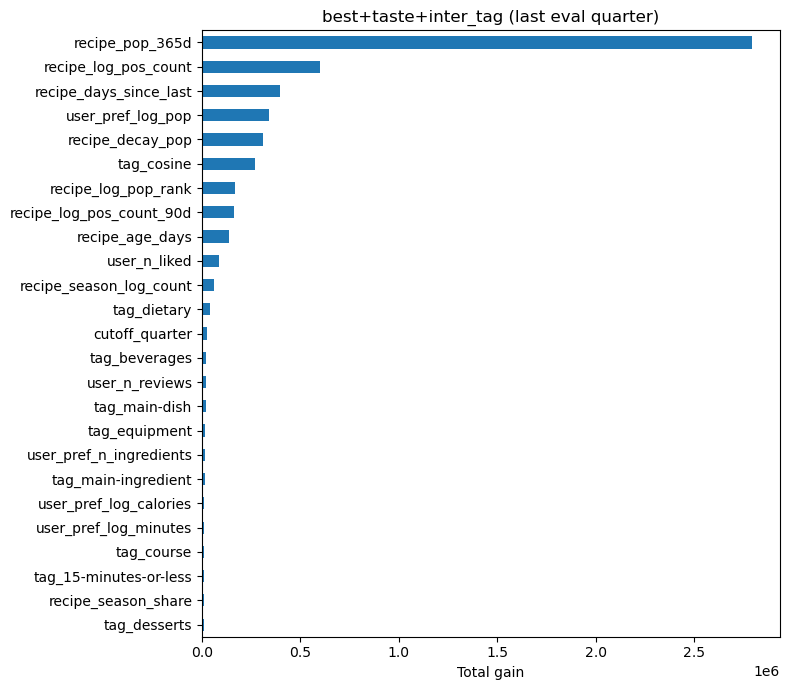

In [15]:
best_overall = max(GROUPS, key=lambda n: results[n]["NDCG"])
m = models[best_overall]
imp = pd.Series(m.model_.feature_importance("gain"), index=m.feature_names_).sort_values(ascending=False).head(25)
imp.iloc[::-1].plot.barh(figsize=(8, 7)); plt.xlabel("Total gain")
plt.title(f"{best_overall} (last eval quarter)"); plt.tight_layout(); plt.show()